<a href="https://colab.research.google.com/github/KritiMagar/CSC425_spam_detection/blob/main/CSC425_Milestone3_Spam_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import zipfile
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Download UCI SMS Spam Collection dataset directly
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam.zip"
urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("sms_data")

# Load tab-separated dataset
df = pd.read_csv("sms_data/SMSSpamCollection", sep='\t', names=['label', 'message'])
print("Raw Dataset Shape:", df.shape)
print(df.head())

Raw Dataset Shape: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


Number of duplicate messages found: 403
Cleaned Dataset Shape: (5169, 2)

Class Distribution after dropping duplicates:
       Count  Percentage (%)
label                       
ham     4516       87.366996
spam     653       12.633004


/tmp/ipykernel_953/236093661.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette='Blues_d')


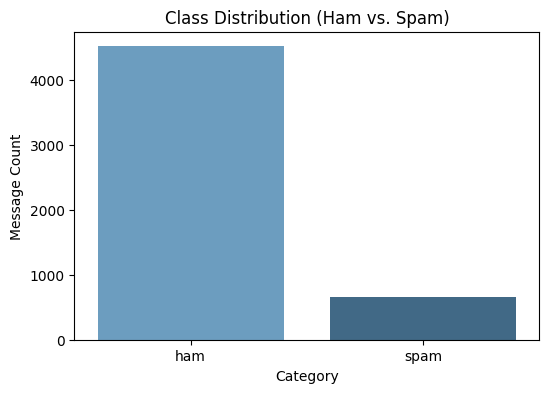

In [19]:
# 1. Check & Drop Duplicates
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate messages found: {duplicates_count}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Cleaned Dataset Shape: {df.shape}")

# 2. Binary Label Encoding (ham = 0, spam = 1)
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

# 3. Class Imbalance Check
class_counts = df['label'].value_counts()
class_percentages = df['label'].value_counts(normalize=True) * 100
print("\nClass Distribution after dropping duplicates:")
print(pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_percentages}))

# Plot Class Distribution
plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='Blues_d')
plt.title("Class Distribution (Ham vs. Spam)")
plt.ylabel("Message Count")
plt.xlabel("Category")
plt.savefig("class_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

In [20]:
# 1. Stratified Split (80% Train, 20% Test)
X = df['message']
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")
print("\nTrain class ratio:\n", y_train.value_counts(normalize=True))
print("\nTest class ratio:\n", y_test.value_counts(normalize=True))

# 2. Fit TF-IDF Vectorizer ONLY on training set (avoids data leakage)
tfidf = TfidfVectorizer(lowercase=True, stop_words='english', max_features=3000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"\nVocabulary size: {len(tfidf.vocabulary_)} features")
print(f"X_train_tfidf shape: {X_train_tfidf.shape}")
print(f"X_test_tfidf shape: {X_test_tfidf.shape}")

Training set size: 4135 samples
Testing set size: 1034 samples

Train class ratio:
 target
0    0.873761
1    0.126239
Name: proportion, dtype: float64

Test class ratio:
 target
0    0.873308
1    0.126692
Name: proportion, dtype: float64

Vocabulary size: 3000 features
X_train_tfidf shape: (4135, 3000)
X_test_tfidf shape: (1034, 3000)


In [21]:
# Baseline 1: Majority Class Dummy ("Always Ham")
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_tfidf, y_train)
y_pred_dummy = dummy.predict(X_test_tfidf)

# Baseline 2: Multinomial Naive Bayes Prototype
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluation Function
def evaluate_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return {'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}

results = pd.DataFrame([
    evaluate_model("Majority Class Baseline (Always Ham)", y_test, y_pred_dummy),
    evaluate_model("Multinomial Naive Bayes (Prototype)", y_test, y_pred_nb)
])

print("\n--- MODEL PERFORMANCE COMPARISON ---")
print(results.to_string(index=False))

print("\nDetailed Naive Bayes Classification Report:")
print(classification_report(y_test, y_pred_nb, target_names=['Ham', 'Spam']))


--- MODEL PERFORMANCE COMPARISON ---
                               Model  Accuracy  Precision   Recall  F1-Score
Majority Class Baseline (Always Ham)  0.873308        0.0 0.000000  0.000000
 Multinomial Naive Bayes (Prototype)  0.973888        1.0 0.793893  0.885106

Detailed Naive Bayes Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       903
        Spam       1.00      0.79      0.89       131

    accuracy                           0.97      1034
   macro avg       0.99      0.90      0.94      1034
weighted avg       0.97      0.97      0.97      1034



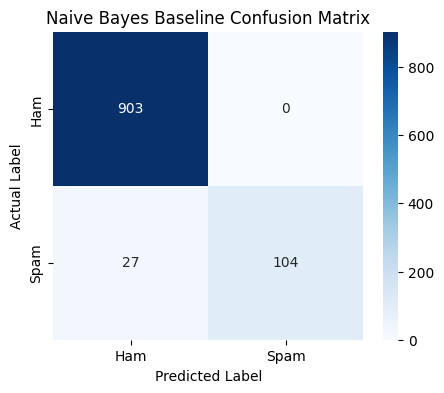


--- SAMPLE PREDICTIONS PIPELINE TEST ---
Message: "Hey Kriti, are we still meeting at the university library at 3 PM?"
Predicted Class: HAM (Legitimate)

Message: "URGENT! You have won a $1,000 Walmart Gift Card. Click here to claim your reward now: http://tinyurl.com/fake-win"
Predicted Class: SPAM (Junk)

Message: "Can you please pick up some milk on your way home tonight?"
Predicted Class: HAM (Legitimate)

Message: "FREE entry into our weekly £1000 prize draw. Text CLAIM to 87121 now to claim your entry!"
Predicted Class: SPAM (Junk)



In [22]:
# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title("Naive Bayes Baseline Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.savefig("confusion_matrix_nb.png", dpi=300, bbox_inches='tight')
plt.show()

# Sample Live Predictions
sample_messages = [
    "Hey Kriti, are we still meeting at the university library at 3 PM?",
    "URGENT! You have won a $1,000 Walmart Gift Card. Click here to claim your reward now: http://tinyurl.com/fake-win",
    "Can you please pick up some milk on your way home tonight?",
    "FREE entry into our weekly £1000 prize draw. Text CLAIM to 87121 now to claim your entry!"
]

sample_features = tfidf.transform(sample_messages)
sample_preds = nb_model.predict(sample_features)
labels_map = {0: "HAM (Legitimate)", 1: "SPAM (Junk)"}

print("\n--- SAMPLE PREDICTIONS PIPELINE TEST ---")
for msg, pred in zip(sample_messages, sample_preds):
    print(f"Message: \"{msg}\"")
    print(f"Predicted Class: {labels_map[pred]}\n")

# MILESTONE 3:  Logistic Regression and Threshold Tuning


I have my Naive Bayes baseline from Milestone 2,
I am testing a Logistic Regression model on the same
TF-IDF features to see if it improves spam detection.

Model Comparison (Default 0.50 Threshold)


,Model,Accuracy,Precision,Recall,F1-Score
0,Dummy Baseline (Always Ham),87.33%,0.00%,0.00%,0.00%
1,Multinomial Naive Bayes,97.39%,100.00%,79.39%,88.51%
2,Logistic Regression (Default 0.5),95.94%,97.85%,69.47%,81.25%


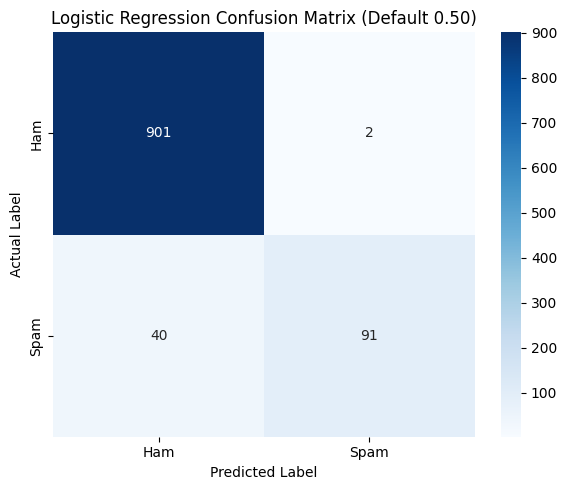

In [23]:
from sklearn.linear_model import LogisticRegression

#  Train Logistic Regression on the exact same TF-IDF features
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

#  Make predictions on the test set
y_pred_lr = lr_model.predict(X_test_tfidf)

#  Calculate evaluation metrics for Logistic Regression
lr_acc = accuracy_score(y_test, y_pred_lr)
lr_prec = precision_score(y_test, y_pred_lr)
lr_rec = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)

#  Re-calculate Naive Bayes metrics for side-by-side comparison
y_pred_nb = nb_model.predict(X_test_tfidf)
nb_acc = accuracy_score(y_test, y_pred_nb)
nb_prec = precision_score(y_test, y_pred_nb)
nb_rec = recall_score(y_test, y_pred_nb)
nb_f1 = f1_score(y_test, y_pred_nb)

#  Print side-by-side comparison table
comparison_df = pd.DataFrame({
    'Model': ['Dummy Baseline (Always Ham)', 'Multinomial Naive Bayes', 'Logistic Regression (Default 0.5)'],
    'Accuracy': ['87.33%', f'{nb_acc*100:.2f}%', f'{lr_acc*100:.2f}%'],
    'Precision': ['0.00%', f'{nb_prec*100:.2f}%', f'{lr_prec*100:.2f}%'],
    'Recall': ['0.00%', f'{nb_rec*100:.2f}%', f'{lr_rec*100:.2f}%'],
    'F1-Score': ['0.00%', f'{nb_f1*100:.2f}%', f'{lr_f1*100:.2f}%']
})

print("Model Comparison (Default 0.50 Threshold)")
display(comparison_df)

#  Plot Confusion Matrix for Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Logistic Regression Confusion Matrix (Default 0.50)')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig('confusion_matrix_lr.png', dpi=300)
plt.show()

At the default 0.50 cutoff, Logistic Regression missed 40
 spam texts because most of the dataset is ham.
 Here, I test lower probability thresholds
 (from 0.50 down to 0.20) and plot a Precision-Recall
 curve to find a better balance between catching spam and
 not blocking normal messages.

Logistic Regression Threshold Tuning Results


,Threshold,Accuracy,Precision,Recall,F1-Score,False Positives (Blocked Ham),False Negatives (Missed Spam)
0,0.50,95.94%,97.85%,69.47%,81.25%,2,40
1,0.40,96.91%,97.14%,77.86%,86.44%,3,29
2,0.35,97.20%,96.36%,80.92%,87.97%,4,25
3,0.30,97.29%,93.28%,84.73%,88.80%,8,20
4,0.25,97.39%,91.94%,87.02%,89.41%,10,17
5,0.20,97.20%,89.23%,88.55%,88.89%,14,15


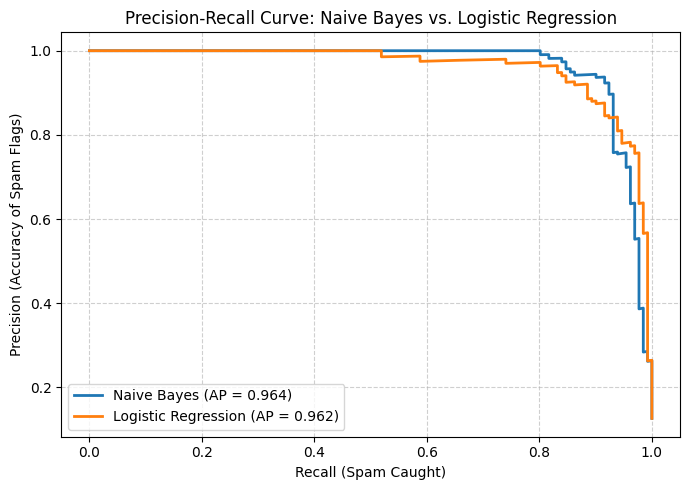

In [24]:
from sklearn.metrics import precision_recall_curve, average_precision_score

#  Get predicted probabilities for the spam class (class 1)
y_probs_lr = lr_model.predict_proba(X_test_tfidf)[:, 1]
y_probs_nb = nb_model.predict_proba(X_test_tfidf)[:, 1]

#  Test multiple decision thresholds for Logistic Regression
thresholds = [0.50, 0.40, 0.35, 0.30, 0.25, 0.20]
results = []

for thresh in thresholds:
    preds = (y_probs_lr >= thresh).astype(int)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()

    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    results.append({
        'Threshold': f'{thresh:.2f}',
        'Accuracy': f'{acc*100:.2f}%',
        'Precision': f'{prec*100:.2f}%',
        'Recall': f'{rec*100:.2f}%',
        'F1-Score': f'{f1*100:.2f}%',
        'False Positives (Blocked Ham)': fp,
        'False Negatives (Missed Spam)': fn
    })

thresh_df = pd.DataFrame(results)
print("Logistic Regression Threshold Tuning Results")
display(thresh_df)

# Plot Precision-Recall Curve comparing Naive Bayes vs. Logistic Regression
prec_nb, rec_nb, _ = precision_recall_curve(y_test, y_probs_nb)
prec_lr, rec_lr, _ = precision_recall_curve(y_test, y_probs_lr)

ap_nb = average_precision_score(y_test, y_probs_nb)
ap_lr = average_precision_score(y_test, y_probs_lr)

plt.figure(figsize=(7, 5))
plt.plot(rec_nb, prec_nb, label=f'Naive Bayes (AP = {ap_nb:.3f})', linewidth=2)
plt.plot(rec_lr, prec_lr, label=f'Logistic Regression (AP = {ap_lr:.3f})', linewidth=2)
plt.title('Precision-Recall Curve: Naive Bayes vs. Logistic Regression')
plt.xlabel('Recall (Spam Caught)')
plt.ylabel('Precision (Accuracy of Spam Flags)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('precision_recall_curve.png', dpi=300)
plt.show()

#Error Analysis (0.25 Threshold)

With 0.25 giving the best F1-score at 89.41%, I plotted the updated confusion matrix and looked at a few specific spam texts—comparing the ones Logistic Regression caught on its own versus the ones neither model caught.

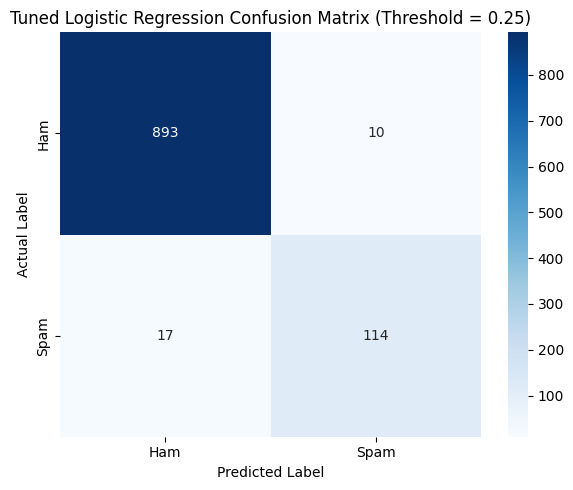

Total spam in test set: 131
Spam missed by Naive Bayes (27) that Tuned LR caught: 12
Hard spam messages missed by BOTH models: 15

Sample Spam Messages Caught by Tuned LR (0.25) that Naive Bayes Missed
- [LR Prob: 0.406] Thanks for the Vote. Now sing along with the stars with Karaoke on your mobile. For a FREE link just reply with SING now.
- [LR Prob: 0.289] Send a logo 2 ur lover - 2 names joined by a heart. Txt LOVE NAME1 NAME2 MOBNO eg LOVE ADAM EVE 07123456789 to 87077 Yahoo! POBox36504W45WQ TxtNO 4 no ads 150p.
- [LR Prob: 0.714] Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visionsms.com Text stop to stopCost 150p 08712400603
- [LR Prob: 0.305] Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 JANINExx Calls£1/minMobsmoreLKPOBOX177HP51FL
- [LR Prob: 0.337] TheMob>Hit the link to get a premium Pink Panther game, the new no. 1 from Sugababes, a crazy Zebra animation or

In [25]:
#  Confusion Matrix for Tuned Logistic Regression (Threshold = 0.25)
best_thresh = 0.25
y_pred_lr_tuned = (y_probs_lr >= best_thresh).astype(int)

cm_lr_tuned = confusion_matrix(y_test, y_pred_lr_tuned)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr_tuned, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title(f'Tuned Logistic Regression Confusion Matrix (Threshold = {best_thresh})')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig('confusion_matrix_lr_tuned.png', dpi=300)
plt.show()

# Inspect False Negatives (Actual Spam predicted as Ham)
# Reconstruct test messages using y_test index
test_df = pd.DataFrame({
    'Message': df.loc[y_test.index, 'message'],
    'Actual': y_test,
    'NB_Pred': y_pred_nb,
    'LR_Tuned_Pred': y_pred_lr_tuned,
    'LR_Spam_Prob': np.round(y_probs_lr, 3)
})

missed_by_both = test_df[(test_df['Actual'] == 1) & (test_df['NB_Pred'] == 0) & (test_df['LR_Tuned_Pred'] == 0)]
caught_only_by_tuned_lr = test_df[(test_df['Actual'] == 1) & (test_df['NB_Pred'] == 0) & (test_df['LR_Tuned_Pred'] == 1)]

print(f"Total spam in test set: {(test_df['Actual'] == 1).sum()}")
print(f"Spam missed by Naive Bayes (27) that Tuned LR caught: {len(caught_only_by_tuned_lr)}")
print(f"Hard spam messages missed by BOTH models: {len(missed_by_both)}\n")

print("Sample Spam Messages Caught by Tuned LR (0.25) that Naive Bayes Missed")
for idx, row in caught_only_by_tuned_lr.head(5).iterrows():
    print(f"- [LR Prob: {row['LR_Spam_Prob']}] {row['Message']}")

print("\nSample Hard Spam Messages Missed by BOTH Models")
for idx, row in missed_by_both.head(8).iterrows():
    print(f"- [LR Prob: {row['LR_Spam_Prob']}] {row['Message']}")